# Do Chicago Neighborhoods with More Sanitation Complaints Have Worse Food Inspections?
### A ZIP-code analysis of 311 sanitation complaints and CDPH food inspections, 2011–2025

**BA780 · Cohort B · Team 03 · Final Project**

**Data:** City of Chicago Data Portal: *Food Inspections* (Chicago Department of Public Health) and *311 Service Requests: Sanitation Code Complaints*, distributed as five ZIP archives in the [team repository](https://github.com/idanm-commiting/Sanitation-Project). The notebook downloads them automatically into `data/` on first run.

## Executive summary

**Stakeholder and objective.** The Chicago Department of Public Health (CDPH) must decide where to focus limited routine food-inspection and prevention resources. We test whether ZIP codes with more 311 sanitation complaints have worse food-inspection outcomes, and whether this relationship is useful for targeting inspections **without replacing risk-based coverage elsewhere**.

**Method.** We cleaned **244,005 pass/fail food inspections** and **245,373 de-duplicated sanitation complaints** from 2011–2025, then compared the two datasets across **57 ZIP codes** (covering 97.9% of inspections and 95.3% of complaints). We used ZIP-level correlations, complaint quartiles, food-code violations, comparisons within inspection risk and purpose, annual correlations, and a within-ZIP over-time check.

**Key findings**
1. **Between-ZIP association.** ZIPs with more complaints show higher inspection failure rates (Pearson r = 0.56) and more recorded pest/garbage citations (r = 0.57); both associations have p < 0.001.
2. **A graded cross-sectional pattern.** Between the lowest- and highest-complaint ZIP quartiles, inspection failure rates increase from **18.1% to 24.7%**, and pest/garbage citation rates from **17.5% to 28.0%**.
3. **Facility conditions show especially large differences.** Among 2019–2025 inspections, the largest violation gaps include physical facilities (+16.0 percentage points), cleaning of food-contact and non-food-contact surfaces (+10.9 points), toilet facilities (+8.2), and insects/rodents (+7.7).
4. **The association remains visible in several subgroup checks, but not all tests.** It appears within establishment risk categories, within inspection purposes, and as a positive between-ZIP association in each annual sample. However, **within a ZIP, higher-than-usual complaint years do not correspond to reliably higher fail rates** (p = 0.64).
5. **Targeting opportunity with an important blind spot.** The twelve highest-scoring ZIPs account for 39% of complaints and 20% of inspections among the 57 analyzed ZIPs, with a 27.6% inspection failure rate. Separately, **ten ZIPs have relatively few complaints but above-median failure rates**; complaint counts alone would miss them.

**Actions proposed for CDPH.** (1) Trial a multi-year ZIP complaint indicator alongside existing inspection criteria, not as a replacement for them. (2) Coordinate facility-cleanliness and pest outreach with Streets & Sanitation in candidate ZIPs. (3) Keep a minimum inspection presence in low-complaint, high-failure areas. (4) Test benefits in a limited pilot with comparable non-pilot ZIPs before expanding; add population, number of licensed establishments, and reporting-access information to assess fairness and alternative explanations.


## Contents
1. Introduction and motivation
2. Project proposal and data sources
3. Team Assignment recap
4. Data loading and preparation
5. Team Assignment charts, refreshed (Figures 1–5)
6. Is there a ZIP-level relationship? (Figures 6–8)
7. Is the link specific to sanitation? (Figures 9–10)
8. Does it survive robustness checks? (Figures 11–14)
9. Where should the city act first? (Figure 15)
10. Conclusion and recommendations
11. Challenges
12. References
13. Generative AI disclosure

## 1. Introduction and motivation

Chicago watches the cleanliness of its neighborhoods through two systems that never talk to each other. Residents file roughly **16,000 sanitation complaints a year** through 311 about overflowing carts, rodents and illegal dumping. Separately, CDPH inspectors complete about **16,000 pass/fail food inspections a year**, and more than one in five fail.

If the two signals line up, the city may have a low-cost **geographic screening indicator** for prioritizing follow-up analysis, but a complaint count alone is not a validated risk score. Inspectors could use it to pick which areas to canvass first, and the departments could coordinate pest-control and food-safety outreach. If the signals do *not* line up, using complaints this way would misdirect scarce inspectors.

**Why read this analysis:** it answers a practical targeting question with data the city already publishes. It also shows what the complaint signal can and cannot be used for, which matters as much as the headline correlation.

**Decision-maker:** CDPH food-inspection planners, coordinating where appropriate with the Chicago Department of Streets & Sanitation. We distinguish **observed association** from causation or proof that a complaint concerned a particular restaurant.

## 2. Project proposal and data sources

**Problem statement.** Do Chicago ZIP codes with more 311 sanitation complaints have worse food-inspection outcomes, and if so, where should the city focus?

| Section | Question of interest |
|---|---|
| 6 | Is complaint volume associated with inspection failure across ZIP codes? How strong is the association, and where is it concentrated? |
| 7 | Is the association specific to sanitation-type violations (pests, garbage, facility cleanliness)? |
| 8 | Does it survive differences in risk mix and inspection purpose, and does it hold over time and within a ZIP? |
| 9 | Which ZIP codes should be prioritized? |

| Dataset | Publisher | Unit of observation | Raw rows | Key fields used |
|---|---|---|---|---|
| [Food Inspections](https://data.cityofchicago.org/Health-Human-Services/Food-Inspections/4ijn-s7e5) | Chicago Dept. of Public Health | One inspection of one establishment | 315,488 | Inspection ID, Results, Risk, Inspection Type, Violations, Zip, Latitude/Longitude, Inspection Date |
| [311 Sanitation Code Complaints](https://data.cityofchicago.org/Service-Requests/311-Service-Requests-Sanitation-Code-Complaints-Hi/me59-5fac) (historical + current, combined by the team) | City of Chicago 311 | One resident service request | 266,702 | Request Number, Status, ZIP Code, Latitude/Longitude, Created Date |

**Approach.** We stack (concatenate) both sources into one table, clean each record type, and aggregate both to **ZIP code**. ZIP is the finest geography that both datasets record reliably: the inspection data has no ward or community-area field, and street addresses rarely match between the two (see Section 4). All rates are computed on full calendar years, 2011–2025.
**A priori hypotheses and decisions.** These are testable expectations, not findings:

| Hypothesis | Expected relationship | What CDPH could do if supported |
|---|---|---|
| H1: Geographic co-location | Higher multi-year sanitation-complaint volume will be associated with a higher ZIP-level inspection failure rate. | Investigate additional routine canvass coverage in consistently high-signal ZIPs. |
| H2: Sanitation specificity | Higher complaint volumes will also be associated with higher recorded pest/garbage citation rates. | Coordinate pest- and refuse-focused preventive outreach. |
| H3: Alternative explanations | The geographic relationship will remain visible within risk groups, inspection purposes, and individual years. | Explore whether the geographic indicator adds information beyond current inspection categories. |
| H4: Short-term warning | Years with above-usual complaint counts within a ZIP will also have above-usual failure rates. | Only if supported, explore complaint spikes as a scheduling trigger; otherwise use multi-year patterns. |

**Analytic caution.** ZIP totals are not per-resident complaint rates, inspection visits are not random, and we do not control for neighborhood income, density or licensed-business counts. Hence these tests identify associations rather than causal effects or a validated allocation rule.


## 3. Team Assignment recap

In the Team Assignment ([`B03-Chicago-Food-Inspection-And-Sanitation.ipynb`](B03-Chicago-Food-Inspection-And-Sanitation.ipynb)) we profiled each dataset **separately** and deliberately did not link them. Key results:

- **Cleaning.** We removed 7,272 complaints the city had marked as duplicates and 807 repeated request numbers, and excluded non-outcome inspection results (*No Entry*, *Out of Business*, ...) from fail-rate denominators.
- **Complaints.** Volume peaked in 2016 (19,970) and bottomed in 2019 (12,260). The ten busiest ZIPs held 36% of complaints, led by 60620. Community area 25 and ward 6 led the other geographic rankings.
- **Inspections.** 23.0% of 2019–2025 inspections failed. *Low*-risk establishments failed more often than *High*-risk ones (25.9% vs. 22.9%). Long-term-care facilities had the highest fail rate among common facility types, and violation code 55 (physical facilities) was the most frequent finding among failures.
- **Open question carried forward:** *do the complaint hot spots and the inspection results line up?* This final phase answers it.

Figures 1–5 below refresh the Team Assignment charts on the 2011–2025 window. We replaced the community-area and ward rankings with two inspection-side charts (fail rate by year and by risk category). The final question is ZIP-based and needs both datasets in view.

## 4. Data loading and preparation

### 4.1 Load and stack the two sources
The loader downloads each archive once, caches it in `data/`, and renames the shared fields (`Street Address`, `ZIP Code`, `Record Date`) so the two record types line up. We then **concatenate** them into one long table, `combined_df`, and use `Record Type` to tell them apart.

**Why concatenate instead of merging on address?** An earlier version joined inspections to complaints on exact street address and year. Only about 1% of complaints matched, for two reasons:
- Most sanitation complaints are filed at homes, not restaurants.
- Address formats differ between the datasets (`5024 S Wolcott (1900W)` vs. `5024 S WOLCOTT AVE`).

The join also duplicated an inspection row for every matching complaint. Stacking the records and aggregating each type to ZIP avoids both problems.

**Reproduction:** The loader first uses ZIP archives already in `data/`. If absent, it downloads them from the team repository. Run the notebook top to bottom in a network-enabled Jupyter environment; `pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy` and `geopandas` are needed, and Figure 8b uses Chicago’s public ZIP boundary GeoJSON. Figure 3 uses only the complaint coordinates and does not require map tiles.

In [1]:
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile, is_zipfile
import shutil
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MultipleLocator, PercentFormatter, StrMethodFormatter
from scipy import stats
from IPython.display import display

BASE_URL = "https://raw.githubusercontent.com/idanm-commiting/Sanitation-Project/main/"
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
FOOD_FILES = ["Food_Inspections_part_1.zip", "Food_Inspections_part_2a.zip",
              "Food_Inspections_part_2b.zip", "Food_Inspections_part_3.zip"]
COMPLAINT_FILE = "311_Sanitation_Combined_2010_2026.zip"


def load_github_zip(filename, record_type):
    """Download and cache a ZIP, then read all CSV members without extracting."""
    archive_path = DATA_DIR / filename
    if not archive_path.exists() or not is_zipfile(archive_path):
        print(f"Downloading {filename} ...", flush=True)
        temporary_path = archive_path.with_suffix(".zip.part")
        with urlopen(BASE_URL + filename, timeout=120) as response:
            with temporary_path.open("wb") as destination:
                shutil.copyfileobj(response, destination)
        if not is_zipfile(temporary_path):
            raise ValueError(f"The download for {filename} is not a valid ZIP file.")
        temporary_path.replace(archive_path)

    frames = []
    with ZipFile(archive_path) as archive:
        csv_members = [
            name for name in archive.namelist()
            if name.lower().endswith(".csv") and not name.startswith("__MACOSX/")
        ]
        if not csv_members:
            raise ValueError(f"No CSV files found in {filename}.")
        for member in csv_members:
            with archive.open(member) as csv_file:
                frame = pd.read_csv(csv_file, low_memory=False)
            frame.columns = frame.columns.str.strip()
            # Align shared fields before stacking the two kinds of records.
            frame = frame.rename(columns={
                "Created Date": "Creation Date",
                "Address": "Street Address",
                "Zip": "ZIP Code",
            })
            date_column = "Creation Date" if record_type == "311 complaint" else "Inspection Date"
            frame["Record Date"] = pd.to_datetime(
                frame[date_column], errors="coerce", format="mixed"
            )
            frame["Record Type"] = record_type
            frame["Source File"] = filename
            frames.append(frame)
    return pd.concat(frames, ignore_index=True, sort=False)


df_food = pd.concat(
    [load_github_zip(f, "Food inspection") for f in FOOD_FILES], ignore_index=True, sort=False
)
df_311 = load_github_zip(COMPLAINT_FILE, "311 complaint")

# Stack both sources into one long table. Shared fields (Street Address, ZIP Code,
# Latitude/Longitude, Record Date) line up; "Record Type" tells the two apart.
combined_df = pd.concat([df_food, df_311], ignore_index=True, sort=False)
combined_df["Year"] = combined_df["Record Date"].dt.year

display(combined_df.groupby("Record Type").agg(
    rows=("Record Type", "size"),
    first_record=("Record Date", "min"),
    last_record=("Record Date", "max"),
))

,rows,first_record,last_record
Record Type,,,
311 complaint,266702,2010-01-24,2026-09-24 00:05:38
Food inspection,315488,2010-01-04,2026-09-14 00:00:00


In [2]:
# One look for every chart: seaborn's white-grid theme, blue for single-series charts,
# and a light-to-dark blue palette for the four complaint quartiles (Q1 = fewest complaints).
sns.set_theme(style="whitegrid", rc={
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "grid.color": "#e1e0d9", "legend.frameon": False,
})
BLUE, ORANGE, RED, GRAY, LIGHT_GRAY = "#2a78d6", "#eb6834", "#e34948", "#52514e", "#c3c2b7"
QUARTILE_PALETTE = {"Q1": "#86b6ef", "Q2": "#3987e5", "Q3": "#256abf", "Q4": "#104281"}
pd.set_option("display.max_columns", 12)

### 4.2 Clean each record type

| Issue | Decision | Why |
|---|---|---|
| Repeated IDs | Keep one row per `Inspection ID` / `Request Number` | Count each event once |
| Complaints marked "Dup" by the city | Drop | They are not independent complaints |
| Non-outcome results (*No Entry*, *Out of Business*, *Not Ready*, ...) | Exclude from rates | No pass/fail decision was made |
| Partial years (2010 complaints are sparse; 2026 is incomplete) | Keep 2011–2025 | Compare like-for-like full years |
| ZIP stored as float or with junk values | Normalize to a five-digit string, otherwise `<NA>` | Consistent grouping key |
| Violation codes renumbered by the July 2018 food code | Flag sanitation issues by **keyword** (rodent, insect, roach, mice, pest, garbage, refuse) for all years; compare codes only for 2019–2025 | Keep the measure consistent across eras |
| ~100 spellings of `Inspection Type` | Collapse to five purposes (routine canvass, complaint-driven, license, re-inspection, other) | Needed for the Section 8 robustness check |

In [3]:
YEARS = range(2011, 2026)   # comparable full years (exclude sparse 2010 and partial 2026)
OUTCOMES = ["Pass", "Pass w/ Conditions", "Fail"]
SANITATION_PATTERN = r"RODENT|INSECT|ROACH|MICE|MOUSE|VERMIN|PEST|GARBAGE|REFUSE"

# Each inspection is one ID; keep only records with a scored outcome in 2011–2025.
food_raw = combined_df[combined_df["Record Type"] == "Food inspection"]
food_unique = food_raw.drop_duplicates("Inspection ID")
food_outcomes = food_unique[food_unique["Results"].isin(OUTCOMES)]
inspections = food_outcomes[food_outcomes["Year"].isin(YEARS)].copy()

# Complaints marked 'Dup' are not independent requests. Subsequently keep one row per ID.
calls_raw = combined_df[combined_df["Record Type"] == "311 complaint"]
calls_nonduplicate_status = calls_raw.loc[~calls_raw["Status"].str.contains("Dup", case=False, na=False)]
calls_unique = calls_nonduplicate_status.drop_duplicates("Request Number")
complaints = calls_unique[calls_unique["Year"].isin(YEARS)].copy()

# Audit reports numbers REMOVED separately from numbers REMAINING at each step.
audit = pd.DataFrame({
    "Cleaning step": ["Original source rows", "Repeated IDs removed", "City-marked duplicate requests removed",
                      "Unique records after deduplication", "Non-outcome inspections excluded",
                      "Pass/fail outcome records before year filter", "Final records (2011–2025)"],
    "Food inspections": [len(food_raw), len(food_raw)-len(food_unique), pd.NA,
                         len(food_unique), len(food_unique)-len(food_outcomes),
                         len(food_outcomes), len(inspections)],
    "311 complaints": [len(calls_raw), len(calls_nonduplicate_status)-len(calls_unique),
                       len(calls_raw)-len(calls_nonduplicate_status),
                       len(calls_unique), pd.NA, pd.NA, len(complaints)]
})
display(audit.set_index("Cleaning step"))

# Reconcile the audit with the source and flag accidental duplicate counting.
assert len(food_raw) - (len(food_raw) - len(food_unique)) == len(food_unique)
assert len(calls_raw) - (len(calls_raw) - len(calls_nonduplicate_status)) - (len(calls_nonduplicate_status) - len(calls_unique)) == len(calls_unique)

# Normalize ZIP codes consistently across datasets. Unparseable ZIPs remain missing.
for frame in [inspections, complaints]:
    frame["Year"] = frame["Year"].astype(int)
    zip_code = pd.to_numeric(frame["ZIP Code"], errors="coerce").astype("Int64").astype("string")
    frame["zip"] = zip_code.where(zip_code.str.fullmatch(r"\d{5}", na=False))

inspections["failed"] = (inspections["Results"] == "Fail").astype(int)
inspections["sanitation_violation"] = (inspections["Violations"].fillna("").str.upper()
                                       .str.contains(SANITATION_PATTERN).astype(int))
inspections["risk"] = inspections["Risk"].map(
    {"Risk 1 (High)": "High", "Risk 2 (Medium)": "Medium", "Risk 3 (Low)": "Low"})
inspection_type = inspections["Inspection Type"].fillna("").str.lower()
inspections["purpose"] = np.select(
    [inspection_type.str.contains("re-insp|reinsp"), inspection_type.str.contains("complaint"),
     inspection_type.str.contains("canvass"), inspection_type.str.contains("license")],
    ["Re-inspection", "Complaint-driven", "Routine canvass", "License"], default="Other")

print(f"Unknown ZIP: {inspections['zip'].isna().mean():.2%} of inspections; "
      f"{complaints['zip'].isna().mean():.2%} of complaints.")
assert inspections["Inspection ID"].is_unique and complaints["Request Number"].is_unique
assert inspections["Results"].isin(OUTCOMES).all()
assert inspections["Year"].between(2011, 2025).all() and complaints["Year"].between(2011, 2025).all()


,Food inspections,311 complaints
Cleaning step,,
Original source rows,315488,266702
Repeated IDs removed,0,807
City-marked duplicate requests removed,<NA>,7272
Unique records after deduplication,315488,258623
Non-outcome inspections excluded,44641,<NA>
Pass/fail outcome records before year filter,270847,<NA>
Final records (2011–2025),244005,245373


Unknown ZIP: 0.01% of inspections; 4.68% of complaints.


**Takeaway and decision:** **244,005** scored inspections and **245,373** independent sanitation requests remain for 2011–2025. ZIP is missing for about 0.01% of inspections and 4.7% of complaints; the ZIP-level join is practical but does not correct for differences in local reporting or establishment density. **CDPH should treat the geographic results as hypotheses for an inspection pilot, not evidence that individual restaurants generated complaints.**

## 5. Team Assignment charts, refreshed (Figures 1–5)

### 5.1 How has sanitation complaint volume changed over time?

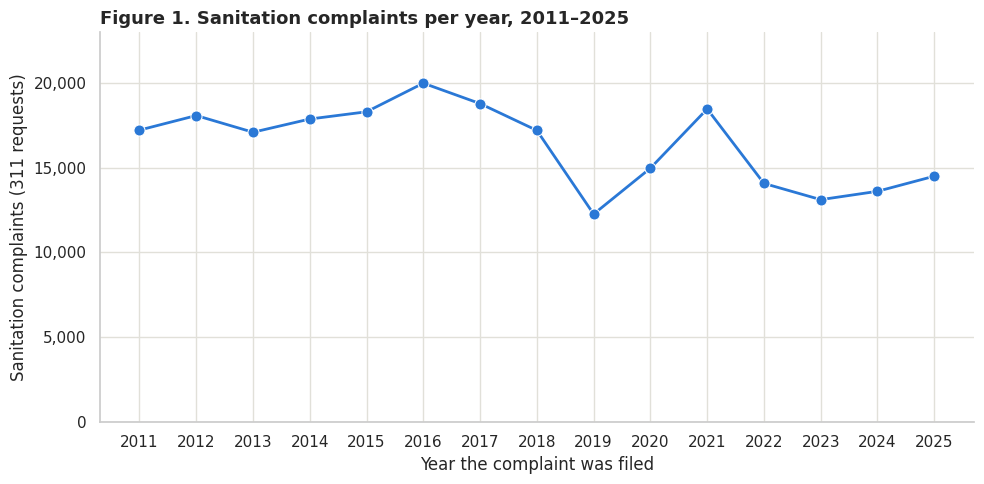

Peak: 2016 (19,970); low: 2019 (12,260); average: 16,358 per year


In [4]:
annual_complaints = complaints["Year"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(x=annual_complaints.index, y=annual_complaints.values, color=BLUE,
             marker="o", markersize=8, linewidth=2, ax=ax)
ax.set_xticks(list(YEARS))
ax.set_ylim(0, annual_complaints.max() * 1.15)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set(xlabel="Year the complaint was filed", ylabel="Sanitation complaints (311 requests)",
       title="Figure 1. Sanitation complaints per year, 2011–2025")
plt.tight_layout()
plt.show()

print(f"Peak: {annual_complaints.idxmax()} ({annual_complaints.max():,}); "
      f"low: {annual_complaints.idxmin()} ({annual_complaints.min():,}); "
      f"average: {annual_complaints.mean():,.0f} per year")

**Answer:** Volume averaged about 16,400 complaints a year. It peaked in 2016 (19,970) and dropped to 12,260 in 2019. The 2019 dip may reflect the city's 311 system transition at the end of 2018 rather than cleaner streets. Because of this, we use *multi-year* totals per ZIP rather than single-year swings to measure complaint burden.

**Implication for CDPH:** A reporting-system change could explain part of the 2019 dip, so avoid changing inspector staffing based on a single-year count. First verify whether intake procedures or reporting access changed.

### 5.2 Which ZIP codes generate the most complaints?

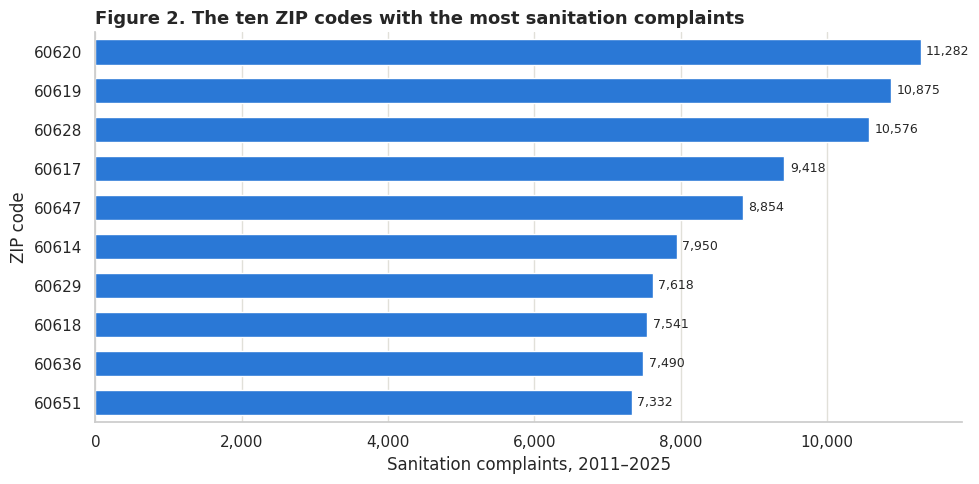

The top ten ZIPs hold 36.2% of all complaints (61 ZIPs appear in the data).


In [5]:
top_zips = complaints["zip"].value_counts().head(10)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=top_zips.values, y=top_zips.index.astype(str), color=BLUE, width=0.65, saturation=1, ax=ax)
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=4, fontsize=9)
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set(xlabel="Sanitation complaints, 2011–2025", ylabel="ZIP code",
       title="Figure 2. The ten ZIP codes with the most sanitation complaints")
plt.tight_layout()
plt.show()

print(f"The top ten ZIPs hold {top_zips.sum() / len(complaints):.1%} of all complaints "
      f"({complaints['zip'].nunique()} ZIPs appear in the data).")

**Answer:** Complaints are concentrated: the ten busiest ZIPs (of 61) account for 36.2% of all requests. The top three, **60620, 60619 and 60628**, are adjacent Far South Side ZIPs, and they reappear at the top of every later chart.

**Next step for CDPH:** Compare these ZIPs with their licensed-establishment counts and resident populations before treating high raw volume as a larger per-business or per-resident burden.

### 5.3 Where are sanitation complaints geographically concentrated?

**Question and expectation (mapping check).** Can aggregate counts reveal geographic concentrations that are hidden by hundreds of thousands of overlapping points? CDPH needs a readable intensity map to identify where a more detailed analysis may be useful.

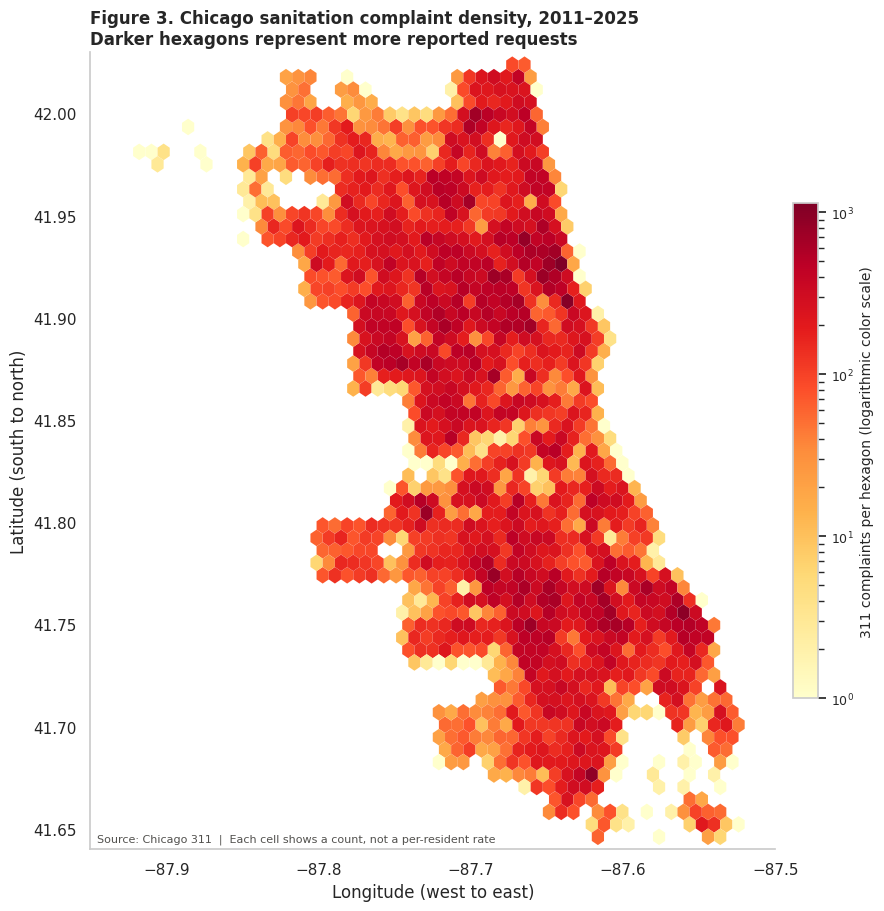

Mapped 245,249 of 245,373 cleaned complaints (99.95%); colors show complaint counts per hexagon, with logarithmic scaling.


In [6]:
from matplotlib.colors import LogNorm

# Aggregate observations into hexagonal geographical bins: ONE colored hexagon
# summarizes its actual number of complaints, instead of one overlapping dot per request.
west, east, south, north = -87.95, -87.50, 41.64, 42.03
map_lat = pd.to_numeric(complaints["Latitude"], errors="coerce")
map_lon = pd.to_numeric(complaints["Longitude"], errors="coerce")
points = complaints.loc[map_lat.between(south, north) & map_lon.between(west, east)].copy()
points["Latitude"] = map_lat.loc[points.index]
points["Longitude"] = map_lon.loc[points.index]

fig, ax = plt.subplots(figsize=(9, 10.2))
hexes = ax.hexbin(points["Longitude"], points["Latitude"],
                  gridsize=56, extent=(west, east, south, north), mincnt=1,
                  cmap="YlOrRd", norm=LogNorm(vmin=1), linewidths=0.12,
                  edgecolors=(1, 1, 1, 0.18), rasterized=True)
bar = fig.colorbar(hexes, ax=ax, fraction=0.034, pad=0.025)
bar.set_label("311 complaints per hexagon (logarithmic color scale)", fontsize=10)
bar.ax.tick_params(labelsize=9)
ax.set_xlim(west, east)
ax.set_ylim(south, north)
ax.set_aspect(1 / np.cos(np.radians(41.85)))
ax.set_xlabel("Longitude (west to east)")
ax.set_ylabel("Latitude (south to north)")
ax.grid(False)
ax.set_title("Figure 3. Chicago sanitation complaint density, 2011–2025\n"
             "Darker hexagons represent more reported requests", loc="left", fontsize=12)
ax.text(0.01, 0.01, "Source: Chicago 311  |  Each cell shows a count, not a per-resident rate",
        transform=ax.transAxes, fontsize=8, color=GRAY,
        bbox={"boxstyle":"round,pad=0.25", "facecolor":"white", "alpha":0.86, "edgecolor":"none"})
plt.tight_layout()
plt.show()

print(f"Mapped {len(points):,} of {len(complaints):,} cleaned complaints ({len(points) / len(complaints):.2%}); "
      "colors show complaint counts per hexagon, with logarithmic scaling.")


**Answer and action:** Nearly all cleaned complaints (**99.95%**) have map coordinates inside the study window. Aggregating the requests into colored hexagons makes local concentrations legible, with a legend that reports complaint counts. **For CDPH:** use the map to locate places for additional review, not to designate dangerous restaurants or compare neighborhoods without population and business-density adjustments. Figure 8b separately maps the ZIP-level complaint/failure groups.

### 5.4 How has the food-inspection fail rate changed over time?

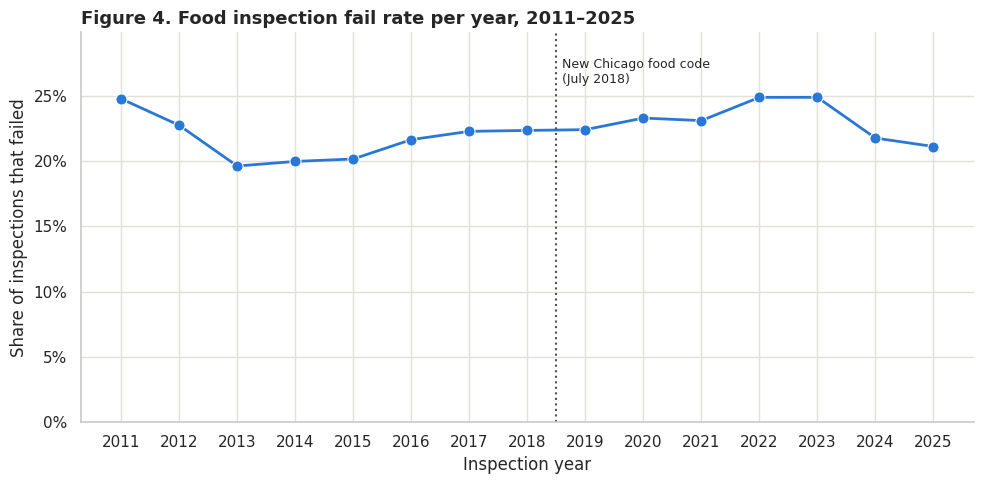

Overall fail rate: 22.2% of 244,005 inspections; range 19.6% (2013) to 24.9% (2023).


In [7]:
annual_fail = inspections.groupby("Year")["failed"].mean()

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(x=annual_fail.index, y=annual_fail.values, color=BLUE,
             marker="o", markersize=8, linewidth=2, ax=ax)
ax.axvline(2018.5, color=GRAY, linestyle=":", linewidth=1.5)
ax.text(2018.6, annual_fail.max() * 1.12, "New Chicago food code\n(July 2018)", fontsize=9, va="top")
ax.set_xticks(list(YEARS))
ax.set_ylim(0, annual_fail.max() * 1.2)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set(xlabel="Inspection year", ylabel="Share of inspections that failed",
       title="Figure 4. Food inspection fail rate per year, 2011–2025")
plt.tight_layout()
plt.show()

print(f"Overall fail rate: {inspections['failed'].mean():.1%} of {len(inspections):,} inspections; "
      f"range {annual_fail.min():.1%} ({annual_fail.idxmin()}) to {annual_fail.max():.1%} ({annual_fail.idxmax()}).")

**Answer:** 22.2% of the 244,005 inspections failed. The yearly rate stayed in a narrow band, from 19.6% (2013) to 24.9% (2023), with no break at the July 2018 food-code change. The relatively narrow citywide range reduces concern about an obvious period-wide break, but does not eliminate differences in ZIP composition, inspection selection or reporting over time.

**Next step for CDPH:** Track the annual fail rate by inspection purpose and location when planning staffing changes, rather than inferring that inspection quality or need is stable from the citywide average.

### 5.5 Do higher-risk establishments fail more often?

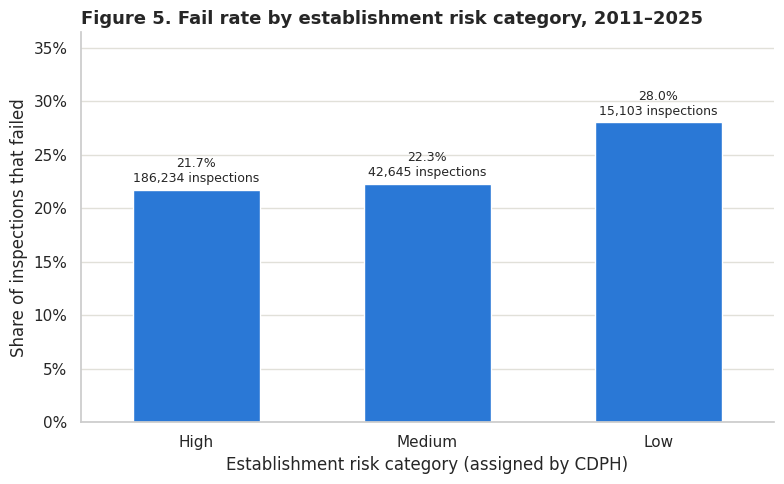

In [8]:
risk_rates = inspections.groupby("risk")["failed"].agg(["mean", "size"]).reindex(["High", "Medium", "Low"])

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=risk_rates.index, y=risk_rates["mean"], color=BLUE, width=0.55, saturation=1, ax=ax)
ax.bar_label(ax.containers[0], padding=3, fontsize=9,
             labels=[f"{rate:.1%}\n{n:,} inspections" for rate, n in zip(risk_rates["mean"], risk_rates["size"])])
ax.set_ylim(0, risk_rates["mean"].max() * 1.3)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set(xlabel="Establishment risk category (assigned by CDPH)", ylabel="Share of inspections that failed",
       title="Figure 5. Fail rate by establishment risk category, 2011–2025")
plt.tight_layout()
plt.show()

**Answer:** No. *Low*-risk establishments fail most often (28.0%), compared with 21.7% for *High*-risk ones, which confirms the Team Assignment finding. CDPH's risk category reflects how complex an establishment's food handling is, not how well it complies. Because the risk mix also differs between neighborhoods, Section 8 checks that the complaint relationship is not just a risk-mix effect.

**Next step for CDPH:** Keep inspection-risk designations distinct from past compliance. Compare neighborhoods *within* each risk category before using the complaint signal in planning.

## 6. Is there a ZIP-level relationship? (Figures 6–8)

We build one row per ZIP from each record type, then line the two up with a column-wise concat on the ZIP index. ZIPs with fewer than 200 inspections or 100 complaints over 15 years are dropped because their rates are too noisy. That leaves **57 ZIPs**, covering 97.9% of inspections and 95.3% of complaints.

**H1 (Figure 6):** We expect a positive ZIP-level association between annualized sanitation complaint volume and the proportion of scored food inspections that fail. **Figure 7 tests whether that relationship is spread across complaint quartiles**, rather than limited to a few outliers. The plots compare geography, not individual business incidents.

In [9]:
MIN_INSPECTIONS, MIN_COMPLAINTS = 200, 100   # drop ZIPs too small for a stable rate

zip_inspections = inspections.groupby("zip").agg(
    inspections=("Inspection ID", "size"),
    establishments=("License #", "nunique"),
    fail_rate=("failed", "mean"),
    sanitation_violation_rate=("sanitation_violation", "mean"),
)
zip_complaints = complaints.groupby("zip").size().rename("complaints")

# Both tables have one row per ZIP, so a column-wise concat lines them up on the ZIP index.
zip_df = pd.concat([zip_inspections, zip_complaints], axis=1, join="inner")
zip_df = zip_df[(zip_df["inspections"] >= MIN_INSPECTIONS) & (zip_df["complaints"] >= MIN_COMPLAINTS)].copy()
zip_df["complaints_per_year"] = zip_df["complaints"] / len(YEARS)
zip_df["quartile"] = pd.qcut(zip_df["complaints_per_year"], 4, labels=["Q1", "Q2", "Q3", "Q4"])
inspections["quartile"] = inspections["zip"].map(zip_df["quartile"])

# Pearson correlation of complaints with each inspection rate
rows = []
for measure in ["fail_rate", "sanitation_violation_rate"]:
    r, p_r = stats.pearsonr(zip_df["complaints_per_year"], zip_df[measure])
    rows.append({"Complaints per year vs.": measure, "Pearson r": r, "Pearson p": p_r})
correlations = pd.DataFrame(rows).set_index("Complaints per year vs.")

print(f"{len(zip_df)} ZIP codes kept; they cover {zip_df['inspections'].sum() / len(inspections):.1%} "
      f"of inspections and {zip_df['complaints'].sum() / len(complaints):.1%} of complaints.")
display(correlations.round(4))
display(zip_df.sort_values("complaints", ascending=False).head(3).round(3))

57 ZIP codes kept; they cover 97.9% of inspections and 95.3% of complaints.


,Pearson r,Pearson p
Complaints per year vs.,,
fail_rate,0.5622,0.0
sanitation_violation_rate,0.5665,0.0


,inspections,establishments,fail_rate,sanitation_violation_rate,complaints,complaints_per_year,quartile
zip,,,,,,,
60620,4674,730,0.289,0.356,11282,752.133,Q4
60619,4799,794,0.301,0.368,10875,725.000,Q4
60628,4360,676,0.292,0.371,10576,705.067,Q4


### 6.1 Do ZIP codes with more sanitation complaints fail more food inspections?

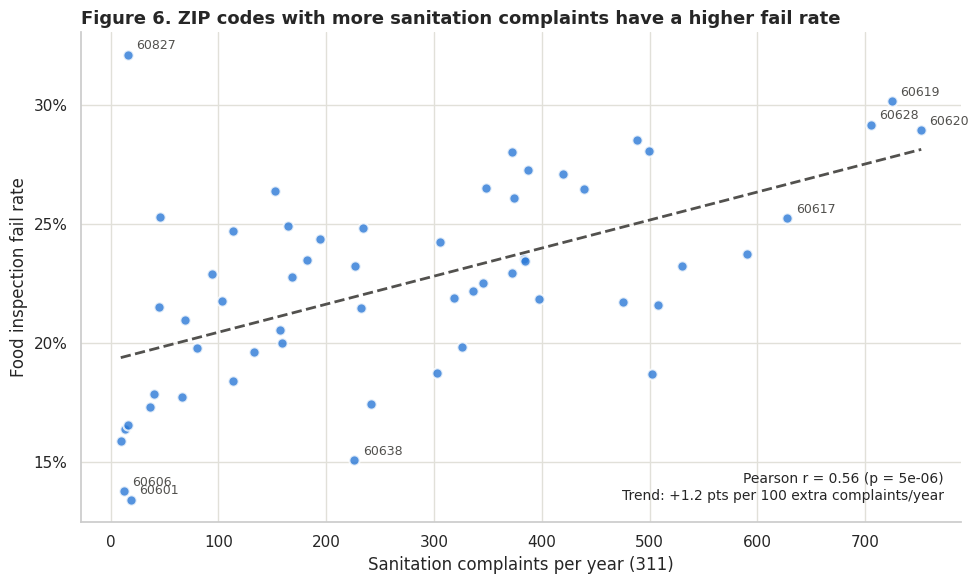

Trend line: 19.3% at zero complaints, +1.18 pts per 100 complaints/year


In [10]:
fit = stats.linregress(zip_df["complaints_per_year"], zip_df["fail_rate"])
corr = correlations.loc["fail_rate"]

fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(data=zip_df, x="complaints_per_year", y="fail_rate", ci=None, color=BLUE,
            scatter_kws={"s": 55, "edgecolor": "white", "linewidths": 1.5},
            line_kws={"color": GRAY, "linestyle": "--", "linewidth": 2}, ax=ax)

# Label the busiest ZIPs and the ZIPs with the highest and lowest fail rates
labeled = (set(zip_df.nlargest(4, "complaints_per_year").index)
           | set(zip_df.nlargest(3, "fail_rate").index) | set(zip_df.nsmallest(3, "fail_rate").index))
for z in labeled:
    ax.annotate(z, (zip_df.loc[z, "complaints_per_year"], zip_df.loc[z, "fail_rate"]),
                xytext=(6, 4), textcoords="offset points", fontsize=9, color=GRAY)

ax.text(0.98, 0.04,
        f"Pearson r = {corr['Pearson r']:.2f} (p = {corr['Pearson p']:.0e})\n"
        f"Trend: +{fit.slope * 100 * 100:.1f} pts per 100 extra complaints/year",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=10)
ax.yaxis.set_major_locator(MultipleLocator(0.05))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set(xlabel="Sanitation complaints per year (311)", ylabel="Food inspection fail rate",
       title="Figure 6. ZIP codes with more sanitation complaints have a higher fail rate")
plt.tight_layout()
plt.show()

print(f"Trend line: {fit.intercept:.1%} at zero complaints, +{fit.slope * 100 * 100:.2f} pts per 100 complaints/year")

**Answer: Yes, moderately strongly.** Across 57 ZIPs, complaint volume and fail rate move together: Pearson r = 0.56, p < 0.001. On the trend line, each additional 100 complaints per year is associated with a fail rate about **1.2 points higher**.

The exceptions are informative:
- **60601 and 60606 (the Loop)** have few complaints and the lowest fail rates.
- **60827** has a high fail rate but few complaints. It straddles the city's southern border, so much of it falls outside Chicago's 311 coverage.

**Action for CDPH:** Use this association to shortlist ZIPs for a data-quality and inspection-capacity review, not as a reason to infer that any specific complaint causes an inspection failure.

### 6.2 Is there a dose-response pattern, or just a few extreme ZIPs?

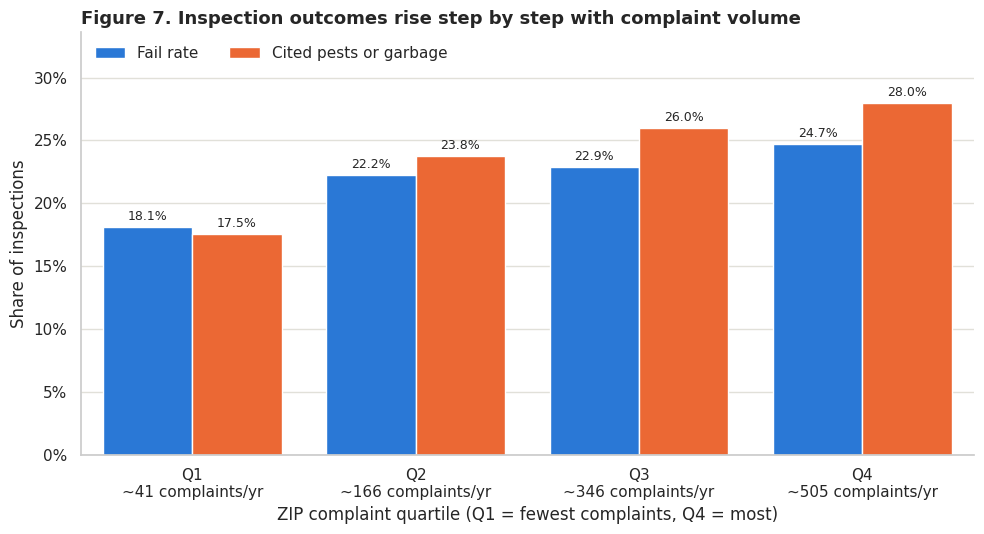

,fail_rate,sanitation_violation_rate,inspections,zips,complaints_per_year
quartile,,,,,
Q1,0.181,0.175,45749,15,40.667
Q2,0.222,0.238,54110,14,166.200
Q3,0.229,0.260,61444,14,346.467
Q4,0.247,0.280,77463,14,505.300


In [11]:
by_quartile = (inspections.dropna(subset=["quartile"])
               .groupby("quartile", observed=True)
               .agg(fail_rate=("failed", "mean"),
                    sanitation_violation_rate=("sanitation_violation", "mean"),
                    inspections=("Inspection ID", "size"),
                    zips=("zip", "nunique")))
by_quartile["complaints_per_year"] = zip_df.groupby("quartile", observed=True)["complaints_per_year"].median()

# Long format: one row per quartile and measure, so seaborn can draw the two measures side by side
plot_data = by_quartile.reset_index().melt(
    id_vars="quartile", value_vars=["fail_rate", "sanitation_violation_rate"],
    var_name="Measure", value_name="Share")
plot_data["Measure"] = plot_data["Measure"].map(
    {"fail_rate": "Fail rate", "sanitation_violation_rate": "Cited pests or garbage"})

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(data=plot_data, x="quartile", y="Share", hue="Measure", palette=[BLUE, ORANGE], saturation=1, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="{:.1%}", padding=3, fontsize=9)
ax.set_xticks(range(4), [f"{q}\n~{c:,.0f} complaints/yr" for q, c in by_quartile["complaints_per_year"].items()])
ax.set_ylim(0, plot_data["Share"].max() * 1.2)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.legend(loc="upper left", ncols=2, title=None)
ax.set(xlabel="ZIP complaint quartile (Q1 = fewest complaints, Q4 = most)", ylabel="Share of inspections",
       title="Figure 7. Inspection outcomes rise step by step with complaint volume")
plt.tight_layout()
plt.show()

display(by_quartile.round(3))

**Answer: A graded descriptive relationship.** Splitting the 57 ZIPs into four equal groups by complaint volume:
- The **fail rate** climbs at every step: 18.1% → 22.2% → 22.9% → 24.7%. Q4 is **36% higher** than Q1.
- **Pest/garbage citations** climb even faster: 17.5% → 28.0%, **60% higher**.

The aggregated quartile pattern is monotonic; it does not establish a causal dose-response or rule out confounding.

**Next step for CDPH:** Test whether the apparent ordering remains after standardizing by numbers of food establishments and neighborhoods’ reporting capacity.

### 6.3 Where are the high-complaint, high-failure ZIP codes?

We split the 57 ZIPs at the median of complaints per year and the median fail rate, which gives four groups (Figure 8a), and then map those groups (Figure 8b). The quadrant chart and map are adapted from the team's Story 3 analysis (`chicago_story1_story3_graft.ipynb`).

**Stakeholder question:** If CDPH uses only raw 311 complaints for targeting, which high-failure ZIPs might receive too little attention? We expect some high-failure, low-complaint ZIPs because complaint volume also reflects who reports.

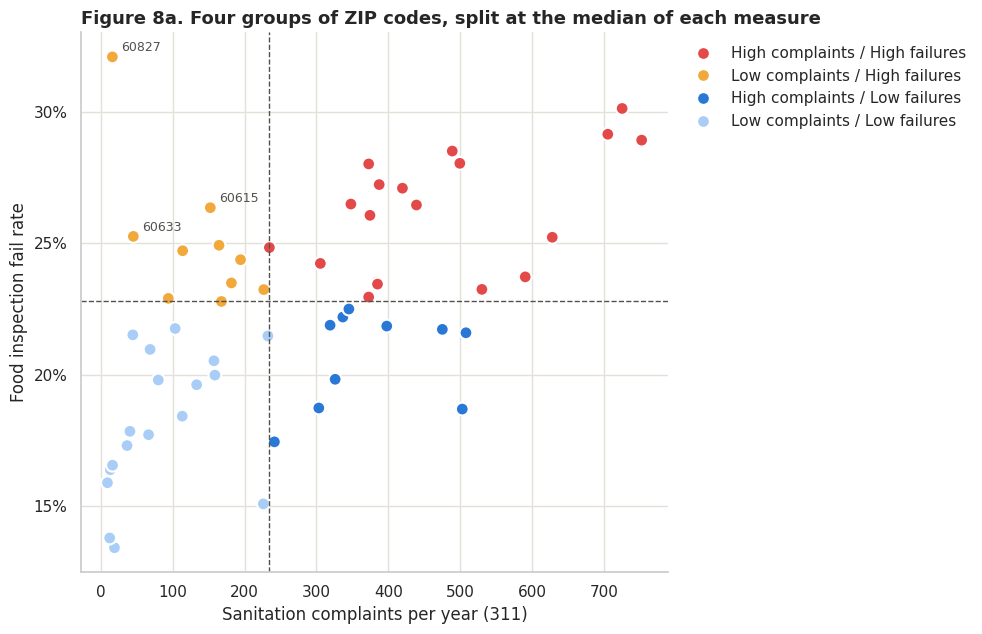

Medians: 235 complaints/year, 22.8% fail rate


,zips,complaints_per_year,fail_rate,sanitation_violation_rate
quadrant,,,,
High complaints / High failures,19,419.533,0.265,0.314
Low complaints / High failures,10,158.467,0.245,0.273
High complaints / Low failures,10,340.867,0.217,0.223
Low complaints / Low failures,18,67.600,0.181,0.188


In [12]:
# Split the ZIPs at the median of each measure into four groups (descriptive, not risk ratings)
QUADRANT_COLORS = {
    "High complaints / High failures": RED,
    "Low complaints / High failures": "#f2a93b",
    "High complaints / Low failures": BLUE,
    "Low complaints / Low failures": "#a9cdf6",
}
x_mid, y_mid = zip_df["complaints_per_year"].median(), zip_df["fail_rate"].median()
high_complaints = zip_df["complaints_per_year"] >= x_mid
high_failures = zip_df["fail_rate"] >= y_mid
zip_df["quadrant"] = np.select(
    [high_complaints & high_failures, ~high_complaints & high_failures, high_complaints & ~high_failures],
    list(QUADRANT_COLORS)[:3], default="Low complaints / Low failures")

fig, ax = plt.subplots(figsize=(10, 6.5))
sns.scatterplot(data=zip_df, x="complaints_per_year", y="fail_rate", hue="quadrant",
                hue_order=list(QUADRANT_COLORS), palette=QUADRANT_COLORS, s=85,
                edgecolor="white", linewidth=1.5, ax=ax)
ax.axvline(x_mid, color=GRAY, linestyle="--", linewidth=1)
ax.axhline(y_mid, color=GRAY, linestyle="--", linewidth=1)

# Label the three worst low-complaint, high-failure ZIPs: problems a complaint-based signal would miss
overlooked = zip_df[zip_df["quadrant"] == "Low complaints / High failures"].nlargest(3, "fail_rate")
for z, row in overlooked.iterrows():
    ax.annotate(z, (row["complaints_per_year"], row["fail_rate"]),
                xytext=(6, 4), textcoords="offset points", fontsize=9, color=GRAY)
ax.yaxis.set_major_locator(MultipleLocator(0.05))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.legend(title=None, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set(xlabel="Sanitation complaints per year (311)", ylabel="Food inspection fail rate",
       title="Figure 8a. Four groups of ZIP codes, split at the median of each measure")
plt.tight_layout()
plt.show()

print(f"Medians: {x_mid:,.0f} complaints/year, {y_mid:.1%} fail rate")
display(zip_df.groupby("quadrant").agg(
    zips=("fail_rate", "size"),
    complaints_per_year=("complaints_per_year", "median"),
    fail_rate=("fail_rate", "median"),
    sanitation_violation_rate=("sanitation_violation_rate", "median"),
).reindex(list(QUADRANT_COLORS)).round(3))

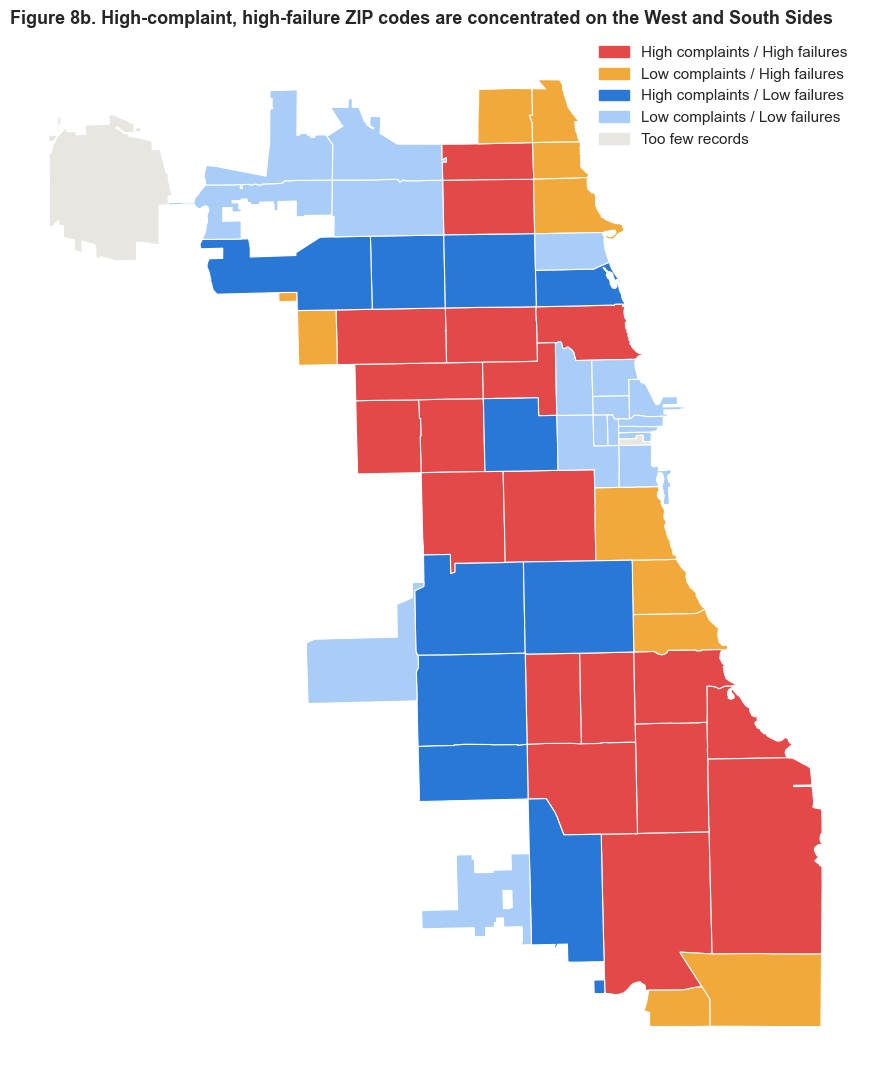

Mapped 57 of 57 analysis ZIPs on 59 city ZIP boundaries.
High complaints / High failures: 60608, 60614, 60617, 60619, 60620, 60621, 60622, 60623, 60624, 60625, 60628, 60636, 60637, 60639, 60644, 60647, 60649, 60651, 60659
Low complaints / High failures: 60615, 60616, 60626, 60633, 60640, 60645, 60653, 60660, 60707, 60827
High complaints / Low failures: 60609, 60612, 60618, 60629, 60632, 60634, 60641, 60643, 60652, 60657
Low complaints / Low failures: 60601, 60602, 60603, 60605, 60606, 60607, 60610, 60611, 60613, 60630, 60631, 60638, 60642, 60646, 60654, 60655, 60656, 60661


In [13]:
import geopandas as gpd
from matplotlib.patches import Patch

# Chicago ZIP boundaries from the city data portal (downloaded once, cached in data/)
boundaries_path = DATA_DIR / "chicago_zip_boundaries.geojson"
if not boundaries_path.exists():
    with urlopen("https://data.cityofchicago.org/resource/unjd-c2ca.geojson?$limit=1000", timeout=120) as response:
        boundaries_path.write_bytes(response.read())
zip_shapes = gpd.read_file(boundaries_path).set_index("zip").join(zip_df["quadrant"])
zip_shapes["quadrant"] = zip_shapes["quadrant"].fillna("Too few records")
map_colors = {**QUADRANT_COLORS, "Too few records": "#e7e6e0"}

fig, ax = plt.subplots(figsize=(9, 11))
for quadrant, color in map_colors.items():
    zip_shapes[zip_shapes["quadrant"] == quadrant].plot(color=color, edgecolor="white", linewidth=0.8, ax=ax)
ax.legend(handles=[Patch(color=color, label=quadrant) for quadrant, color in map_colors.items()],
          loc="upper right")
ax.set_axis_off()
ax.set_title("Figure 8b. High-complaint, high-failure ZIP codes are concentrated on the West and South Sides")
plt.tight_layout()
plt.show()

print(f"Mapped {zip_shapes['quadrant'].ne('Too few records').sum()} of {len(zip_df)} analysis ZIPs "
      f"on {len(zip_shapes)} city ZIP boundaries.")
for quadrant in QUADRANT_COLORS:
    print(f"{quadrant}: {', '.join(sorted(zip_df.index[zip_df['quadrant'] == quadrant]))}")

**Answer: Mostly on the West and South Sides, plus a second group worth watching.** The medians are 235 complaints a year and a 22.8% fail rate.
- **19 ZIPs are high on both** (median 420 complaints a year, 26.5% fail rate, 31.4% pest/garbage citations). Most are on the West Side (60623, 60624, 60644, 60651) and the South Side (60619, 60620, 60628, 60636). Several of the leading ZIPs also appear among the twelve highest-scoring ZIPs in Section 9.
- **10 ZIPs fail often despite few complaints** (median 158 complaints a year, 24.5% fail rate). These are problems a complaint-based signal would miss. They sit along the North Side lakefront (60626, 60640, 60660) and the mid-South lakefront (60615, 60653), plus border ZIPs such as 60827 and 60633 that lie partly outside 311 coverage.
- **18 ZIPs are low on both**, mainly downtown and on the far Northwest and Southwest Sides.

These are descriptive groups, not risk ratings. A ZIP close to a median line could easily fall in the neighboring group.

**Recommended actions by group:** (1) **High complaints / high failures:** review staffing, sanitation enforcement and coordinated prevention; (2) **Low complaints / high failures:** preserve routine CDPH coverage and investigate whether reporting barriers mask problems; (3) **High complaints / low failures:** review whether 311 issues mainly concern streets, housing or other non-restaurant locations; (4) **Low complaints / low failures:** maintain baseline risk-based inspections instead of automatically diverting all resources elsewhere. These categories are screening groups, not validated risk ratings.

## 7. Is the link specific to sanitation? (Figures 9–10)

### 7.1 Are complaints linked to the *sanitation-type* findings in particular?

**H2:** Areas with more sanitation complaints should show higher pest/garbage citation rates, not merely higher overall food-inspection failures. A finding concentrated in sanitation-related issues would support a focused interdepartmental pilot.

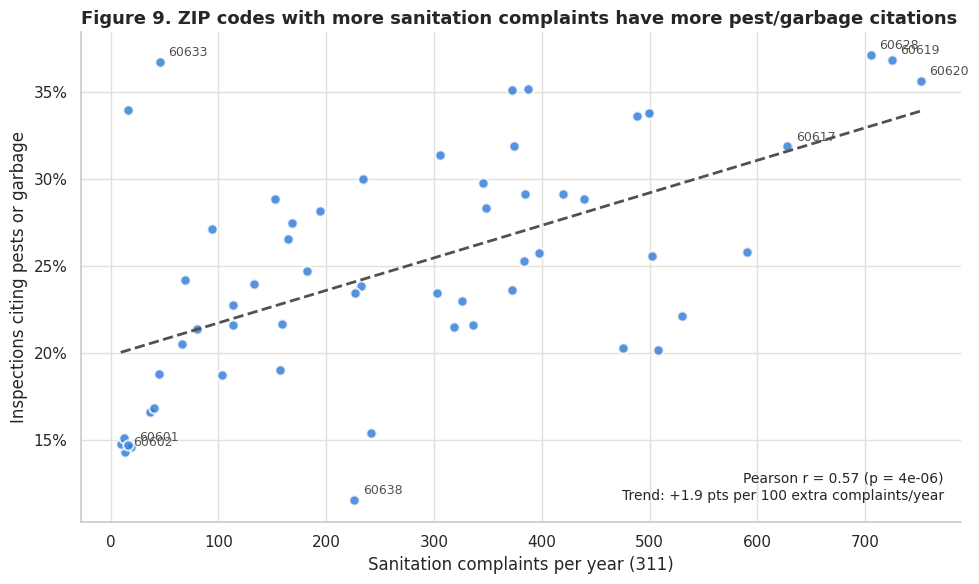

Trend line: 19.8% at zero complaints, +1.87 pts per 100 complaints/year


In [14]:
fit = stats.linregress(zip_df["complaints_per_year"], zip_df["sanitation_violation_rate"])
corr = correlations.loc["sanitation_violation_rate"]

fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(data=zip_df, x="complaints_per_year", y="sanitation_violation_rate", ci=None, color=BLUE,
            scatter_kws={"s": 55, "edgecolor": "white", "linewidths": 1.5},
            line_kws={"color": GRAY, "linestyle": "--", "linewidth": 2}, ax=ax)

# Label the busiest ZIPs and the ZIPs with the highest and lowest citation rates
labeled = (set(zip_df.nlargest(4, "complaints_per_year").index)
           | set(zip_df.nlargest(3, "sanitation_violation_rate").index)
           | set(zip_df.nsmallest(3, "sanitation_violation_rate").index))
for z in labeled:
    ax.annotate(z, (zip_df.loc[z, "complaints_per_year"], zip_df.loc[z, "sanitation_violation_rate"]),
                xytext=(6, 4), textcoords="offset points", fontsize=9, color=GRAY)

ax.text(0.98, 0.04,
        f"Pearson r = {corr['Pearson r']:.2f} (p = {corr['Pearson p']:.0e})\n"
        f"Trend: +{fit.slope * 100 * 100:.1f} pts per 100 extra complaints/year",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=10)
ax.yaxis.set_major_locator(MultipleLocator(0.05))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set(xlabel="Sanitation complaints per year (311)", ylabel="Inspections citing pests or garbage",
       title="Figure 9. ZIP codes with more sanitation complaints have more pest/garbage citations")
plt.tight_layout()
plt.show()

print(f"Trend line: {fit.intercept:.1%} at zero complaints, +{fit.slope * 100 * 100:.2f} pts per 100 complaints/year")

**Answer: Yes, with a steeper descriptive slope for sanitation citations.** The share of inspections citing pests or garbage has nearly the same correlation with complaints (r = 0.57) as the fail rate does. Its slope is about 60% steeper, though: **+1.9 points per 100 complaints a year**, vs. +1.2 for the fail rate. This is the most direct overlap between the datasets, since both describe pests and refuse.

**Next step for CDPH:** Check how consistently inspectors document pest/garbage findings before using this outcome as a pilot evaluation metric.

### 7.2 Which specific violations differ most between high- and low-complaint ZIPs?

**Expected relationship:** If neighborhood conditions matter, building-condition, pest and cleaning-related citations should differ more across complaint quartiles than unrelated violations. Code-level comparisons use 2019–2025 because inspection codes changed in 2018.

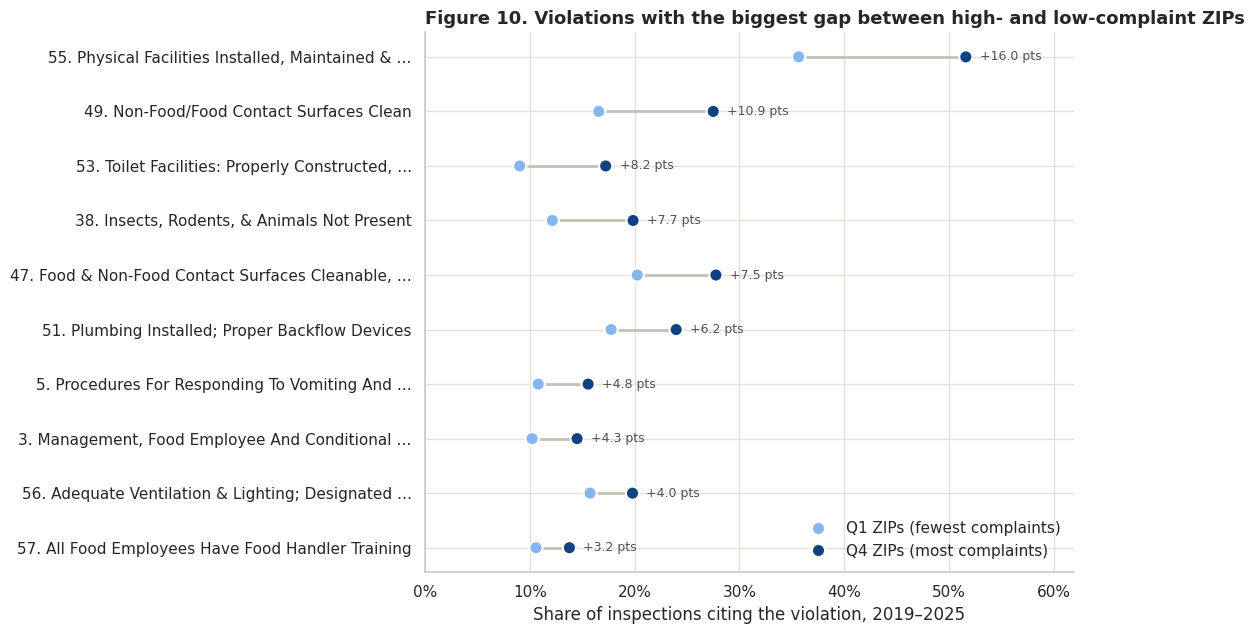

Inspections compared: Q1 = 18,938, Q4 = 33,058


In [15]:
# Split each inspection's violation list into (code, title) pairs. Codes were renumbered with
# the July 2018 food code, so only 2019–2025 inspections are compared here.
recent = inspections[inspections["Year"].between(2019, 2025) & inspections["quartile"].isin(["Q1", "Q4"])]
violations = (recent[["Inspection ID", "quartile", "Violations"]]
              .dropna(subset=["Violations"])
              .assign(segment=lambda d: d["Violations"].str.split("|"))
              .explode("segment"))
violations[["code", "title"]] = violations["segment"].str.extract(r"^\s*(\d+)\.\s*(.*?)\s*(?:- Comments:|$)")
violations = violations.dropna(subset=["code"]).drop_duplicates(["Inspection ID", "code"])

# Share of inspections in each group that cite each code
inspections_per_group = recent.groupby("quartile", observed=True).size()[["Q1", "Q4"]]
share = (violations.groupby(["code", "quartile"], observed=True).size().unstack(fill_value=0)
         [["Q1", "Q4"]].div(inspections_per_group))
share["gap"] = share["Q4"] - share["Q1"]
titles = violations.groupby("code")["title"].first()
share["label"] = (share.index + ". " + titles.reindex(share.index).str.title()).map(
    lambda text: textwrap.shorten(text, width=52, placeholder=" …"))
top_gaps = share[share[["Q1", "Q4"]].max(axis=1) >= 0.05].nlargest(10, "gap")

dots = top_gaps.melt(id_vars="label", value_vars=["Q1", "Q4"], var_name="ZIP group", value_name="share")
dots["ZIP group"] = dots["ZIP group"].map({"Q1": "Q1 ZIPs (fewest complaints)", "Q4": "Q4 ZIPs (most complaints)"})

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.hlines(top_gaps["label"], top_gaps["Q1"], top_gaps["Q4"], color=LIGHT_GRAY, linewidth=2)
sns.scatterplot(data=dots, x="share", y="label", hue="ZIP group", s=90, edgecolor="white", linewidth=1.5,
                palette={"Q1 ZIPs (fewest complaints)": QUARTILE_PALETTE["Q1"],
                         "Q4 ZIPs (most complaints)": QUARTILE_PALETTE["Q4"]},
                zorder=3, ax=ax)
for position, (q4, gap) in enumerate(zip(top_gaps["Q4"], top_gaps["gap"])):
    ax.annotate(f"+{gap * 100:.1f} pts", (q4, position), xytext=(10, 0), textcoords="offset points",
                va="center", fontsize=9, color=GRAY)
ax.set_xlim(0, top_gaps["Q4"].max() * 1.2)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.legend(loc="lower right", title=None)
ax.set(xlabel="Share of inspections citing the violation, 2019–2025", ylabel=None,
       title="Figure 10. Violations with the biggest gap between high- and low-complaint ZIPs")
plt.tight_layout()
plt.show()

print(f"Inspections compared: Q1 = {inspections_per_group['Q1']:,}, Q4 = {inspections_per_group['Q4']:,}")

**Answer: Building condition and cleanliness, not food handling.** We compared 2019–2025 inspections in the highest-complaint quartile (Q4, 33,058 inspections) with the lowest (Q1, 18,938). The biggest gaps were:
- **#55 physical facilities maintained and clean:** +16.0 pts
- **#49 food and non-food contact surfaces clean:** +10.9
- **#53 toilet facilities:** +8.2
- **#38 insects, rodents and animals:** +7.7
- **#47 cleanable surfaces:** +7.5
- **#51 plumbing:** +6.2

Food-handling items such as #3 (management and employee health) and #5 (vomiting/diarrhea procedures) show smaller gaps of about 4 to 5 pts. These differences are consistent with shared physical-environment conditions, but the data cannot establish that neighborhood waste conditions caused the citations.

**CDPH action:** In a pilot, prioritize hands-on building-cleanliness, pest-proofing, plumbing and sanitation guidance; track the cited violation codes at follow-up inspections.

## 8. Does it survive robustness checks? (Figures 11–14)

### 8.1 Is the gap just a difference in risk mix?

**H3:** If the observed geographic relationship is entirely explained by differences in risk mix or inspection purpose, it should substantially disappear when comparing similar inspections. **H4:** If complaints provide a timely warning within ZIPs, unusually high complaint years should also show higher failure rates; Section 8.4 is a more demanding test of this expectation.

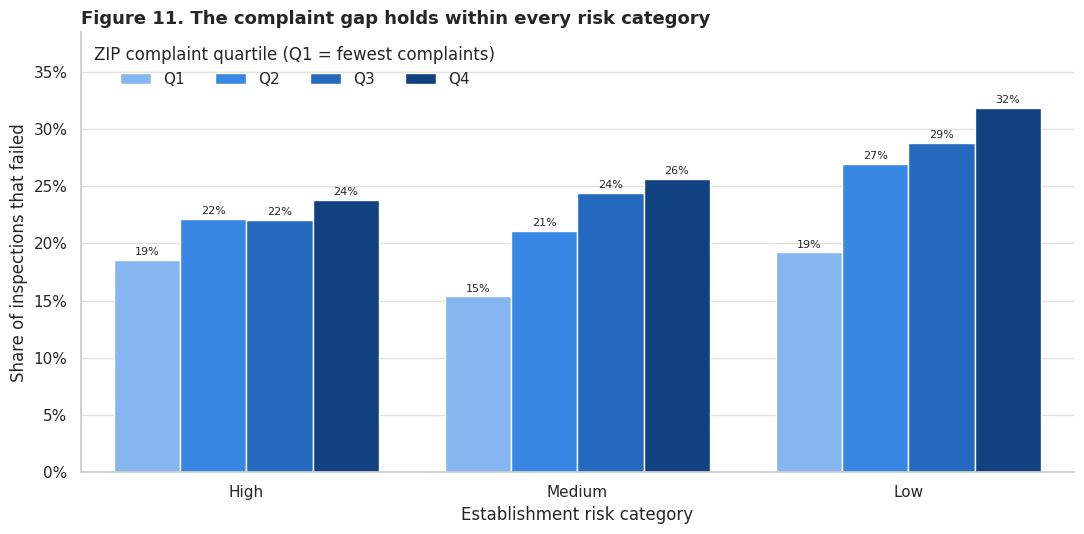

risk,High,Medium,Low
quartile,,,
Q1,0.817,0.146,0.037
Q2,0.791,0.155,0.054
Q3,0.749,0.186,0.065
Q4,0.734,0.190,0.077


In [16]:
in_quartiles = inspections.dropna(subset=["quartile"])

# seaborn averages the 0/1 "failed" column for each risk category and quartile
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.barplot(data=in_quartiles, x="risk", y="failed", hue="quartile", order=["High", "Medium", "Low"],
            hue_order=list(QUARTILE_PALETTE), palette=QUARTILE_PALETTE, errorbar=None, saturation=1, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="{:.0%}", padding=2, fontsize=8)
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.legend(title="ZIP complaint quartile (Q1 = fewest complaints)", ncols=4, loc="upper left")
ax.set(xlabel="Establishment risk category", ylabel="Share of inspections that failed",
       title="Figure 11. The complaint gap holds within every risk category")
plt.tight_layout()
plt.show()

# Is the gap a risk-mix effect? Share of each risk category per quartile:
display(pd.crosstab(in_quartiles["quartile"], in_quartiles["risk"], normalize="index")
        [["High", "Medium", "Low"]].round(3))

**Answer: No.** High-complaint ZIPs do have a different mix: 73% of their inspections are *High*-risk vs. 82% in low-complaint ZIPs, with more *Low*-risk establishments, which fail more often (Figure 5). But the gap appears **within every risk category**:
- *High*: 19% → 24%
- *Medium*: 15% → 26%
- *Low*: 19% → 32%

The descriptive risk-stratified pattern persists, though other unmeasured differences may remain.

**Next step for CDPH:** Pilot the indicator separately within each risk category and compare risk-standardized rates before shifting staff.

### 8.2 Is it because high-complaint ZIPs get more complaint-driven inspections?

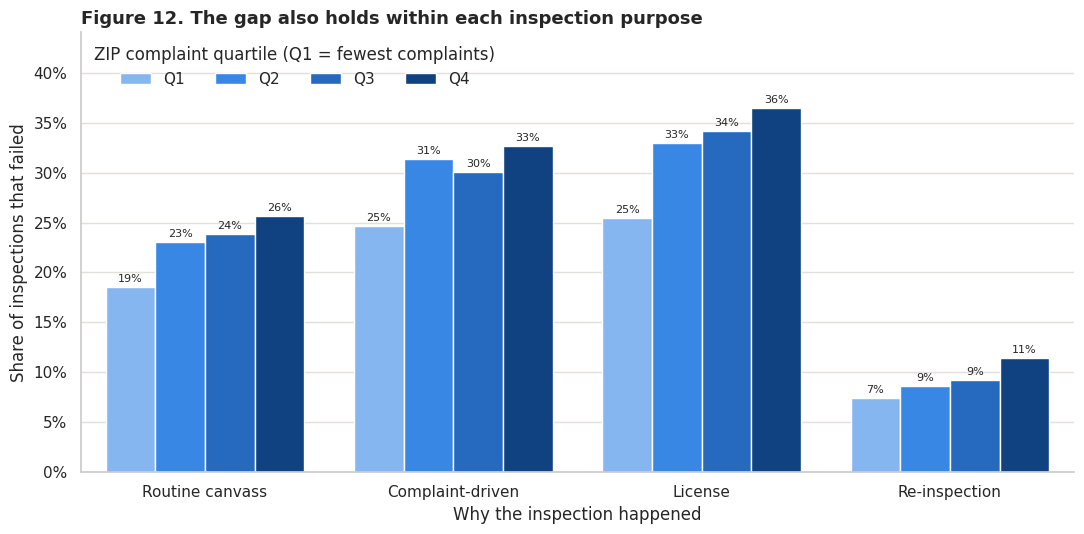

purpose,Routine canvass,Complaint-driven,License,Re-inspection,Other
quartile,,,,,
Q1,0.542,0.121,0.135,0.190,0.012
Q2,0.501,0.141,0.124,0.224,0.011
Q3,0.486,0.136,0.145,0.226,0.008
Q4,0.456,0.145,0.146,0.245,0.008


In [17]:
PURPOSE_ORDER = ["Routine canvass", "Complaint-driven", "License", "Re-inspection"]

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.barplot(data=in_quartiles, x="purpose", y="failed", hue="quartile", order=PURPOSE_ORDER,
            hue_order=list(QUARTILE_PALETTE), palette=QUARTILE_PALETTE, errorbar=None, saturation=1, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="{:.0%}", padding=2, fontsize=8)
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.legend(title="ZIP complaint quartile (Q1 = fewest complaints)", ncols=4, loc="upper left")
ax.set(xlabel="Why the inspection happened", ylabel="Share of inspections that failed",
       title="Figure 12. The gap also holds within each inspection purpose")
plt.tight_layout()
plt.show()

# Inspection mix per quartile: do high-complaint ZIPs simply get more complaint-driven visits?
display(pd.crosstab(in_quartiles["quartile"], in_quartiles["purpose"], normalize="index")
        [PURPOSE_ORDER + ["Other"]].round(3))

**Answer: No.** If high-complaint ZIPs simply received more complaint-triggered visits, which fail more, the gap could be an artifact of inspection purpose. But the mix barely differs: complaint-driven visits are 14.5% of inspections in Q4 vs. 12.1% in Q1. Q4 also has *more* re-inspections (24.5% vs. 19.0%), which rarely fail and would *shrink* the gap.

Within each purpose, the gradient holds:
- **Routine canvass:** 19% → 26%. These are not triggered by any complaint, so this is the cleanest comparison.
- **License inspections:** 25% → 36%.

**Next step for CDPH:** Begin any evaluation with *routine canvass* outcomes, rather than letting complaint-driven inspections mechanically inflate the measured relationship. This remains observational, not a randomized comparison.

### 8.3 Has the relationship held every year?

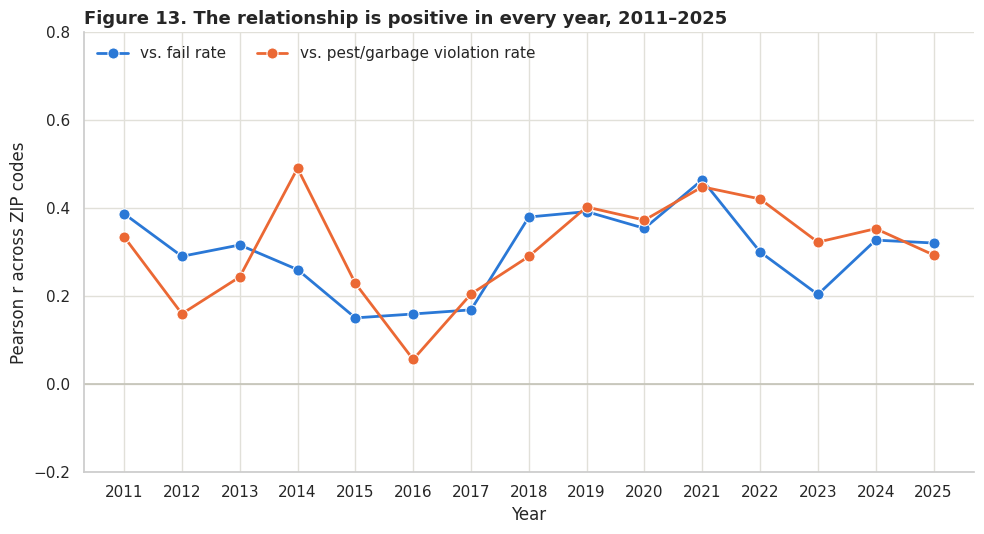

                                  min  mean   max
Correlation                                      
vs. fail rate                    0.15  0.30  0.46
vs. pest/garbage violation rate  0.06  0.31  0.49


In [18]:
# One row per ZIP and year, for ZIP-years with at least 20 inspections
zip_year = (inspections.groupby(["zip", "Year"])
            .agg(n=("Inspection ID", "size"), fail_rate=("failed", "mean"),
                 sanitation_violation_rate=("sanitation_violation", "mean"))
            .join(complaints.groupby(["zip", "Year"]).size().rename("complaints"), how="inner")
            .reset_index())
zip_year = zip_year[(zip_year["n"] >= 20) & zip_year["zip"].isin(zip_df.index)]

# Re-run the ZIP-level correlation separately for each year
rows = []
for year, group in zip_year.groupby("Year"):
    rows.append({
        "Year": year,
        "vs. fail rate": stats.pearsonr(group["complaints"], group["fail_rate"])[0],
        "vs. pest/garbage violation rate": stats.pearsonr(group["complaints"], group["sanitation_violation_rate"])[0],
    })
yearly_r = pd.DataFrame(rows).melt(id_vars="Year", var_name="Correlation", value_name="Pearson r")

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.lineplot(data=yearly_r, x="Year", y="Pearson r", hue="Correlation", palette=[BLUE, ORANGE],
             marker="o", markersize=8, linewidth=2, ax=ax)
ax.axhline(0, color=LIGHT_GRAY, linewidth=1.2)
ax.set_xticks(list(YEARS))
ax.set_ylim(-0.2, 0.8)
ax.legend(loc="upper left", ncols=2, title=None)
ax.set(xlabel="Year", ylabel="Pearson r across ZIP codes",
       title="Figure 13. The relationship is positive in every year, 2011–2025")
plt.tight_layout()
plt.show()

print(yearly_r.groupby("Correlation")["Pearson r"].agg(["min", "mean", "max"]).round(2))

**Answer: Yes.** Re-running the ZIP-level correlation separately for each year gives a positive r in **all 15 years**: 0.15 to 0.46 for the fail rate (mean 0.30) and 0.06 to 0.49 for pest/garbage citations (mean 0.31). Single-year correlations are weaker than the pooled r = 0.56 because one year of inspections per ZIP is a noisier sample, but the sign never flips. Positive signs occur in these annual slices, but the differing magnitudes do not prove stability, statistical significance in every year or immunity to time-varying confounders.

**Next step for CDPH:** Check period-specific coverage and number of inspections before using a single year to prioritize a ZIP.

### 8.4 Within a ZIP, are high-complaint years also high-failure years?

**H4 (short-term trigger):** A ZIP with more complaints than its own usual level should have a higher failure rate in that year if complaint spikes are useful near-term warnings. This test could disconfirm the idea even when the between-ZIP association is strong.

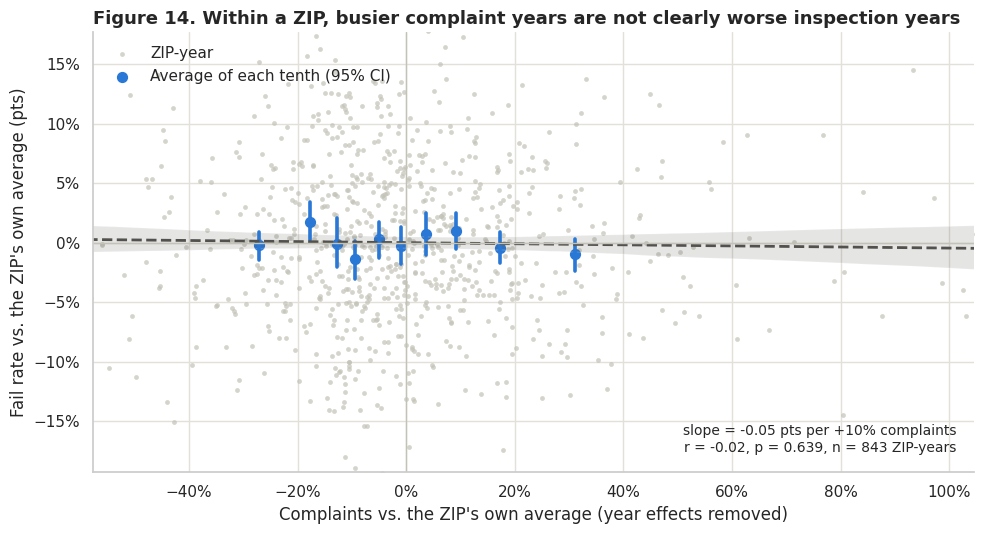

In [19]:
# Within-ZIP test: compare each ZIP-year to that ZIP's own average, then remove citywide
# year effects. If complaints and failures rise and fall together, a ZIP's unusually
# high-complaint years should also be its unusually high-failure years.
panel = zip_year.copy()
panel["complaints_vs_usual"] = panel["complaints"] / panel.groupby("zip")["complaints"].transform("mean") - 1
panel["fail_vs_usual"] = panel["fail_rate"] - panel.groupby("zip")["fail_rate"].transform("mean")
for column in ["complaints_vs_usual", "fail_vs_usual"]:
    panel[column] -= panel.groupby("Year")[column].transform("mean")
fit = stats.linregress(panel["complaints_vs_usual"], panel["fail_vs_usual"])

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.scatterplot(data=panel, x="complaints_vs_usual", y="fail_vs_usual", color=LIGHT_GRAY, s=12,
                linewidth=0, alpha=0.7, label="ZIP-year", ax=ax)
sns.regplot(data=panel, x="complaints_vs_usual", y="fail_vs_usual", x_bins=10, color=BLUE,
            line_kws={"color": GRAY, "linestyle": "--", "linewidth": 2},
            label="Average of each tenth (95% CI)", ax=ax)
ax.axhline(0, color=LIGHT_GRAY, linewidth=1)
ax.axvline(0, color=LIGHT_GRAY, linewidth=1)
ax.set_xlim(panel["complaints_vs_usual"].quantile([0.005, 0.995]))
ax.set_ylim(panel["fail_vs_usual"].quantile([0.005, 0.995]))
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.text(0.98, 0.04, f"slope = {fit.slope * 0.10 * 100:+.2f} pts per +10% complaints\n"
                    f"r = {fit.rvalue:.2f}, p = {fit.pvalue:.3f}, n = {len(panel):,} ZIP-years",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=10)
ax.legend(loc="upper left")
ax.set(xlabel="Complaints vs. the ZIP's own average (year effects removed)",
       ylabel="Fail rate vs. the ZIP's own average (pts)",
       title="Figure 14. Within a ZIP, busier complaint years are not clearly worse inspection years")
plt.tight_layout()
plt.show()

**Answer: No, and this is an important limit.** We compared each ZIP to its own 15-year average and removed citywide year effects. Across 843 ZIP-years, a year with 10% more complaints than usual comes with essentially no change in fail rate: −0.05 pts, r = −0.02, p = 0.64.

**Interpretation:** The evidence supports a *between-place screening association*, not a demonstrated within-ZIP short-term warning. Unmeasured conditions (for example buildings, density, income and commercial mix) could affect both measures; annual aggregation could also hide shorter effects.

**Decision for CDPH:** Do not automatically deploy inspectors when a ZIP has a sudden increase in complaints on the strength of these results. Consider multi-year geographic indicators for a pilot, and test lagged/monthly dynamics only after obtaining suitable data.

## 9. Where should the city act first? (Figure 15)

### 9.1 Which ZIP codes rank high on all three measures?
We score each ZIP by its average percentile rank on complaints per year, fail rate, and pest/garbage citation rate. A score of 1.0 means worst on all three.

**Decision question:** Which ZIPs merit further CDPH review if complaint burden, observed failures, and pest/garbage citations are given equal weight? This is a **transparent screening ranking**, not a validated measure of underlying food-safety risk. The number 12 is a pilot shortlist chosen for comparison, not a statistically optimal cutoff.

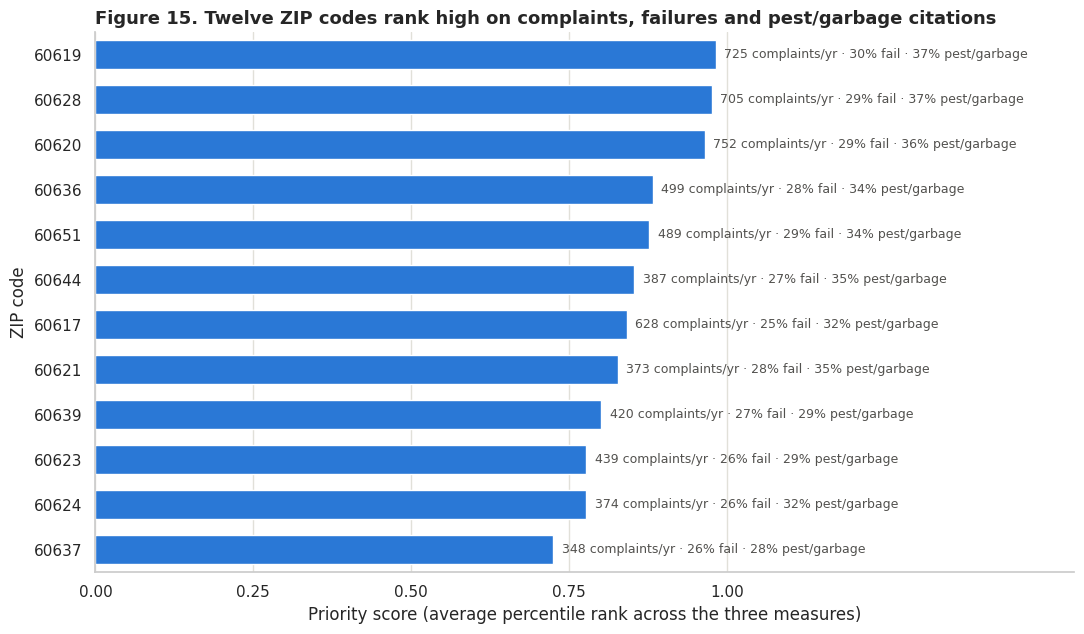

These 12 ZIPs: 39% of complaints, 20% of inspections, fail rate 27.6% vs. 22.4% across all 57 ZIPs.


In [20]:
# Priority score = average percentile rank on the three ZIP measures (1.0 = worst on all three)
measures = ["complaints_per_year", "fail_rate", "sanitation_violation_rate"]
zip_df["priority_score"] = zip_df[measures].rank(pct=True).mean(axis=1)
priority = zip_df.nlargest(12, "priority_score")

fig, ax = plt.subplots(figsize=(11, 6.5))
sns.barplot(x=priority["priority_score"], y=priority.index, color=BLUE, width=0.65, saturation=1, ax=ax)
ax.bar_label(ax.containers[0], padding=6, fontsize=9, color=GRAY, labels=[
    f"{row.complaints_per_year:,.0f} complaints/yr · {row.fail_rate:.0%} fail · {row.sanitation_violation_rate:.0%} pest/garbage"
    for row in priority.itertuples()])
ax.set_xlim(0, 1.55)
ax.set_xticks(np.arange(0, 1.01, 0.25))
ax.set(xlabel="Priority score (average percentile rank across the three measures)", ylabel="ZIP code",
       title="Figure 15. Twelve ZIP codes rank high on complaints, failures and pest/garbage citations")
plt.tight_layout()
plt.show()

print(f"These 12 ZIPs: {priority['complaints'].sum() / zip_df['complaints'].sum():.0%} of complaints, "
      f"{priority['inspections'].sum() / zip_df['inspections'].sum():.0%} of inspections, "
      f"fail rate {np.average(priority['fail_rate'], weights=priority['inspections']):.1%} vs. "
      f"{np.average(zip_df['fail_rate'], weights=zip_df['inspections']):.1%} across all {len(zip_df)} ZIPs.")

**Answer:** Twelve ZIPs stand out, led by **60619, 60628 and 60620**, all of which score above 0.95. Others include 60636, 60651, 60644, 60617 and 60621, mostly on the South and West Sides.

Together these twelve generate **39% of complaints but receive only 20% of inspections**, and they fail **27.6%** of inspections vs. 22.4% across all 57 ZIPs. These relative shares do **not** demonstrate underinspection: more inspections may take place where there are more licensed facilities, and complaint reporting varies geographically. The list is for further review and a controlled pilot, not automatic resource reallocation.

**CDPH next steps:** (1) Review inspection load per licensed establishment in each ZIP. (2) Select a feasible subset for targeted routine visits and sanitation outreach. (3) Compare follow-up violation rates against matched non-pilot ZIPs. (4) Check low-complaint/high-failure ZIPs separately so they are not overlooked.

## 10. Conclusion and recommendations

**What the analysis establishes.** Across the 57 ZIPs meeting minimum sample thresholds, higher multi-year complaint volume is associated with higher inspection failure rates (r = 0.56) and pest/garbage citations (r = 0.57). Both outcomes increase across complaint quartiles, and several sanitation/building-related violation codes have larger observed gaps between high- and low-complaint groups. The positive between-ZIP association is visible across inspection-risk and purpose strata and each annual slice.

**What it does not establish.** The within-ZIP annual comparison does **not** support the expectation that unusual year-to-year complaint spikes predict worse inspection outcomes (p = 0.64). The observations are not randomized, inspection selection and 311 reporting differ geographically, and neither complaint counts nor inspection counts are normalized to residents or licensed facilities. **The analysis does not demonstrate causation, a validated prediction model, or that the priority ZIPs are currently underinspected.**

**Recommendations for the Chicago Department of Public Health (CDPH)**
1. **Test a geographic screening rule, not an automatic staffing change.** Review the 12 highest-scoring ZIPs (Figure 15) alongside current inspection schedules, numbers of licensed establishments, and historic violations. Use multi-year complaint levels rather than one-year spikes.
2. **Protect low-complaint, high-failure areas from being overlooked.** The 10 such ZIPs in Figure 8a should retain baseline routine canvass coverage; verify whether low 311 use reflects fewer issues or barriers to reporting.
3. **Coordinate a targeted prevention pilot.** Work with Chicago Streets & Sanitation in suitable areas on pest-proofing, facility cleanliness, waste handling and sanitation education, using the violation categories in Figure 10 to focus outreach.
4. **Measure impacts before scaling.** Compare pilot ZIPs against comparable non-pilot areas on routine inspection failure rates, pest/garbage citation rates and repeat violations. Track inspection counts and resource cost. An observed improvement would warrant further validation, not automatic causal attribution.

**Data to collect or link next:** licensed restaurant counts and types by ZIP, ZIP-level population and income, 311 reporting access, geographic boundaries for partial ZIPs, and inspection/complaint records at a suitable finer time scale. With those inputs, assess whether complaint levels add predictive value beyond baseline risk, prior inspection performance and local establishment mix.


## 11. Challenges

| Challenge | How we handled it |
|---|---|
| **The address-level merge failed.** Only ~1% of complaints matched an inspection address, and the many-to-many join duplicated inspection rows. | Replaced it with a concatenation of both sources plus ZIP-level aggregation (Section 4.1). Each inspection and complaint is counted once. |
| **Duplicate complaints:** 7,272 city-marked duplicates and 807 repeated request numbers were removed in distinct steps. | Dropped them before counting (Section 4.2 audit table). |
| **Non-outcome inspections:** 44,641 results such as *No Entry* or *Out of Business*. | Excluded from fail-rate denominators. |
| **Partial years:** sparse 2010 complaints and incomplete 2026. | Restricted to full years 2011–2025. |
| **Violation codes changed in July 2018.** | Used a keyword flag for pests/garbage across all years, and compared codes only for 2019–2025. |
| **Small ZIPs give noisy rates.** | Required ≥200 inspections and ≥100 complaints. The 57 remaining ZIPs still cover 98% of inspections and 95% of complaints. |
| **Potential confounding and selection:** risk mix, inspection purpose, year, neighborhood reporting behavior and facility density. | Stratified by risk (Fig. 11) and purpose (Fig. 12), repeated by year (Fig. 13), and ran a within-ZIP test (Fig. 14). |
| **No population denominator** in either dataset. | Kept rates on the inspection side and treated complaint volume as a relative signal. Flagged as the main limitation and the first next step. |
| **Border ZIPs** such as 60827 lie partly outside 311 coverage. | Kept them, but called them out as outliers when interpreting Figure 6. || **Correlation is not predictive validation:** the within-ZIP annual test was not significant (p = 0.64). | We describe the multi-year association as a screening hypothesis, not a short-term warning tool or proof that complaint targeting would improve outcomes. |
| **Unequal complaint reporting and establishment mix:** ZIP complaint totals were not normalized to resident or restaurant counts. | We recommend validating with census/business denominators before reallocating inspection capacity and preserving inspections in low-complaint/high-failure ZIPs. |
| **Map overplotting in the earlier draft.** A separate point for every complaint obscured local variation. | Figure 3 now aggregates requests into a yellow-to-red hexagon count-density display with an explicitly labeled logarithmic count scale. |

## 12. References

- City of Chicago, Department of Public Health. [Food Inspections](https://data.cityofchicago.org/Health-Human-Services/Food-Inspections/4ijn-s7e5), Chicago Data Portal. Inspection records; the dataset description documents the July 1, 2018 change to violation definitions.
- City of Chicago. [311 Service Requests: Sanitation Code Complaints (Historical)](https://data.cityofchicago.org/Service-Requests/311-Service-Requests-Sanitation-Code-Complaints-Hi/me59-5fac) and [311 Service Requests](https://data.cityofchicago.org/Service-Requests/311-Service-Requests/v6vf-nfxy), Chicago Data Portal. Complaint records, combined into one extract by the team.
- City of Chicago. [Boundaries - ZIP Codes](https://data.cityofchicago.org/d/unjd-c2ca), Chicago Data Portal. ZIP code polygons used in Figure 8b.
- City of Chicago. [Data Portal Terms of Use](https://www.chicago.gov/city/en/narr/foia/data_disclaimer.html).
- Team 03. [Sanitation-Project repository](https://github.com/idanm-commiting/Sanitation-Project). Source of the five data archives.
- Team 03. Prior team assignment and working notebooks used for cleaning decisions, refreshed figures, and the quadrant chart/map adapted in Figures 8a–8b (combined team contributions).
- Software documentation: [pandas](https://pandas.pydata.org/docs/), [NumPy](https://numpy.org/doc/), [Matplotlib](https://matplotlib.org/stable/), [seaborn](https://seaborn.pydata.org/), [GeoPandas](https://geopandas.org/), [SciPy `stats`](https://docs.scipy.org/doc/scipy/reference/stats.html) (Pearson correlation, linear regression).
- Course materials: *BA780 Final Project Deliverable & Presentation Rubric*, used for the notebook structure.

## 13. Generative AI disclosure

Our team used generative AI for assistance during this project's preparation; the use below is reported by task and section so it can be checked against the actual notebook.

- **Claude (Anthropic, via Claude Code in VS Code) — earlier final draft:** helped diagnose why the address-level merge produced few matches; suggested ZIP aggregation; assisted with data preparation in Section 4, analysis code in Sections 6–9, the 2019–2025 violation parser, and the visualizations. Claude also helped draft and organize the executive summary, research questions, answers, challenges and conclusion.
- **OpenAI Codex — Team Assignment phase:** helped with earlier cleaning logic, integration and chart adjustments, as disclosed in the initial team deliverable. Relevant parts were carried into the final notebook.
- **ChatGPT (OpenAI) — final revision:** Corrected the cleaning-audit labels and checks (Section 4.2); Assisted with replacing the overlapping Figure 3 point map with a hexagon count-density map and color scale; edited the stated hypotheses, CDPH-specific actions, low-complaint/high-failure discussion, and qualified interpretation of within-ZIP results (Sections 2, 5–11); and revised the reference and disclosure wording.

**Verification and responsibility.** Numerical findings are tied to computed outputs in the notebook. We report the checks actually implemented (unique record IDs, outcome categories, year bounds, cleaning-step reconciliation and the stated analyses); these do not eliminate all data-quality issues or potential confounding. Team members remain responsible for reading, testing, interpreting and accurately presenting the work, including verifying the underlying downloaded datasets in the final execution environment. This notebook contains **16 charts: Figures 1–15 with separate Figures 8a and 8b**.
